In [18]:
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
from typing import TypedDict, Literal, Annotated
from pydantic import BaseModel
from langchain_core.messages import BaseMessage, HumanMessage
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from langchain_community.tools import DuckDuckGoSearchRun
from langgraph.types import interrupt, Command
from langgraph.checkpoint.memory import InMemorySaver
from langchain.tools import tool
import requests
import os

In [19]:
os.environ['LANGCHAIN_PROJECT']='HITL'

In [20]:
load_dotenv()

True

In [21]:
@tool
def get_stock(symbol: str) -> dict:
    """returns the latest price of the stock"""
    url=f'https://www.alphavantage.co/query?function=GLOBAL_QUOTE&symbol={symbol}&apikey=LDJQLEJGNWNWUJS2'
    r=requests.get(url)
    return r.json()

@tool
def buy_stocks(symbol: str, quantity:int, total_price:float) -> str:
    """Buy the given stocks and according to its price"""
    decision=interrupt(f'Approve buying {quantity} {symbol} stocks for this ${total_price:.2f}?')

    if decision == 'yes':
        return f'You Bought {quantity} {symbol} stocks at the total proce of ${total_price:.2f}.'
    else:
        return f'Buying Declined'


In [22]:
model=ChatOpenAI(model='gpt-4o-mini')

In [23]:

tools=[get_stock, buy_stocks]

llm_binded=model.bind_tools(tools)


In [24]:
class mssg(TypedDict):
    messages:Annotated[list[BaseMessage], add_messages]

In [25]:
def chatnode(state:mssg):
    rs=llm_binded.invoke(state['messages'])
    return {'messages':[rs]}

toolnode=ToolNode(tools)

In [26]:
graph=StateGraph(mssg)

graph.add_node('chatnode', chatnode)
graph.add_node('tools', toolnode)

graph.add_edge(START, 'chatnode')

graph.add_conditional_edges('chatnode', tools_condition)

graph.add_edge('tools', 'chatnode')


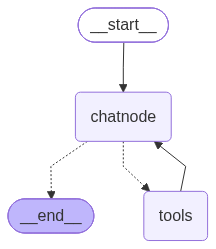

In [33]:
check=InMemorySaver()
wf=graph.compile(checkpointer=check)
wf

In [34]:
config={'run_name':'HITL', 'configurable':{'thread_id':'thread2'}}

In [35]:

rs=wf.invoke({'messages':[HumanMessage(content="what is the price of apple share?")]}, config=config)
rs['messages'][-1].content

'The current price of an Apple share (AAPL) is $336.67.'

In [36]:
rs1=wf.invoke({'messages':[HumanMessage(content="Buy 10 stocks of tesla share?")]}, config=config)
print(rs1.get("__interrupt__")[0].value)


Approve buying 10 TSLA stocks for this $3778.10?


In [57]:
rs1

{'messages': [HumanMessage(content='what is the price of apple share?', additional_kwargs={}, response_metadata={}, id='677bd552-6c67-460a-a4ea-2097428468b1'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 15, 'prompt_tokens': 87, 'total_tokens': 102, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_c19ce61615', 'id': 'chatcmpl-EO42uz3fI01MIEKeL7zktgeQZu39I', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a0a0cc-1889-7b63-8915-e86347a7dcb8-0', tool_calls=[{'name': 'get_stock', 'args': {'symbol': 'AAPL'}, 'id': 'call_AeAX0vNBiC7DL8jBIVGAXH9j', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 87, 'ou

In [58]:
decision=input("Approve(yes/no)")
rs2=wf.invoke(Command(resume=decision), config=config)
print(rs2['messages'][-1].content)

The attempt to buy 10 Tesla shares (TSLA) has been declined. Let me know if you need any further assistance or if you would like to try again!


In [12]:
get_stock.invoke({'symbol':"AAPL"})

{'Global Quote': {'01. symbol': 'AAPL',
  '02. open': '316.9800',
  '03. high': '327.3000',
  '04. low': '314.7300',
  '05. price': '325.1300',
  '06. volume': '53167388',
  '07. latest trading day': '2026-09-01',
  '08. previous close': '316.8500',
  '09. change': '8.2800',
  '10. change percent': '2.6132%'}}